# Week 07: Data Visualization Lab


## Shan_72387_PFAI_Week07


## Part A: Setup, Directory Preparation, and Data Validation

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt


DATA_PATH = Path("../week06/data/processed/students_clean.csv")
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


if not DATA_PATH.exists():
    DATA_PATH = Path("week06/data/processed/students_clean.csv")
    FIGURE_DIR = Path("week07/figures")
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)


students = pd.read_csv(DATA_PATH)
print("Data loaded successfully!")
print(f"Dataset Shape: {students.shape} (Rows, Columns)")

Data loaded successfully!
Dataset Shape: (10, 17) (Rows, Columns)


### 1. Schema and Null-Value Verification

In [11]:
required = {"program", "attendance", "final", "weighted_score", "grade"}
missing_cols = required - set(students.columns)

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

print("First 5 records of required fields:")
display(students[sorted(required)].head())

print("\nMissing values per required field:")
print(students[sorted(required)].isna().sum())

First 5 records of required fields:


,attendance,final,grade,program,weighted_score
0,85.0,81.0,B,BSAI,77.7
1,85.0,75.0,B,BSAI,75.5
2,92.0,88.0,B,BSAI,81.6
3,81.0,90.0,B,BSCS,84.7
4,74.0,81.0,C,BSAI,70.1



Missing values per required field:
attendance        0
final             0
grade             0
program           0
weighted_score    0
dtype: int64


### 2. Variable Classification

In [12]:
numerical_cols = students.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = students.select_dtypes(include=["object", "string", "category"]).columns.tolist()

print(f"Numerical Variables ({len(numerical_cols)}):", numerical_cols)
print(f"Categorical Variables ({len(categorical_cols)}):", categorical_cols)

Numerical Variables (6): ['student_id', 'attendance', 'assignment', 'midterm', 'final', 'weighted_score']
Categorical Variables (6): ['name', 'program', 'city', 'admission_date', 'attendance_status', 'grade']


### 3. Exploratory Distributions and Range Check

In [ ]:

display(students[["attendance", "final", "weighted_score"]].describe())

print("--- Program Distribution ---")
print(students["program"].value_counts())

print("\n--- Grade Distribution ---")
print(students["grade"].value_counts())

assert students["attendance"].between(0, 100).all(), "Invalid attendance values detected!"
assert students["final"].between(0, 100).all(), "Invalid final scores detected!"
assert students["weighted_score"].between(0, 100).all(), "Invalid weighted scores detected!"

print("\nAll range and schema checks passed. Checkpoint A verified.")

,attendance,final,weighted_score
count,10.000000,10.000000,10.000000
mean,81.500000,78.600000,75.000000
std,6.637436,15.356504,14.218923
min,69.000000,49.000000,48.100000
25%,79.500000,76.250000,71.450000
50%,81.000000,81.000000,77.650000
75%,85.000000,89.500000,83.925000
max,92.000000,94.000000,90.900000


--- Program Distribution ---
program
BSAI    6
BSCS    2
BSDS    2
Name: count, dtype: int64

--- Grade Distribution ---
grade
B    5
A    2
C    1
D    1
F    1
Name: count, dtype: int64

All range and schema checks passed. Checkpoint A verified.


## Part B — Trend and Relationship Charts

### B1. Line Plot: Ordered Trend

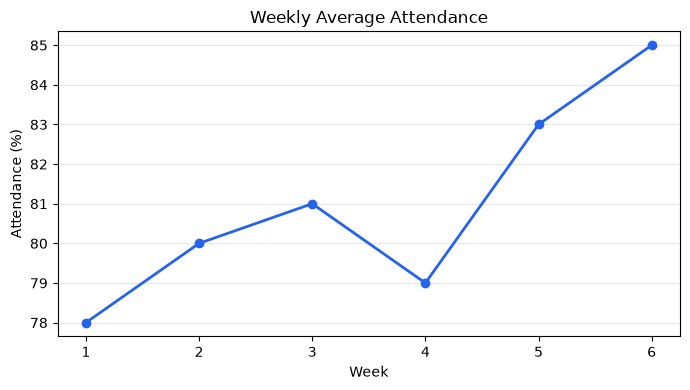

In [14]:

weeks = [1, 2, 3, 4, 5, 6] 
average_attendance = [78, 80, 81, 79, 83, 85] 

fig, ax = plt.subplots(figsize=(7, 4)) 
ax.plot(weeks, average_attendance, marker="o", color="#2563EB", linewidth=2) 
ax.set(title="Weekly Average Attendance", xlabel="Week", ylabel="Attendance (%)") 
ax.set_xticks(weeks) 
ax.grid(axis="y", alpha=0.3) 
fig.tight_layout()


line_plot_path = FIGURE_DIR / "b1_weekly_attendance_trend.png"
fig.savefig(line_plot_path, dpi=300)
plt.show()

### B2. Scatter Plot: Attendance vs Final Marks Relationship

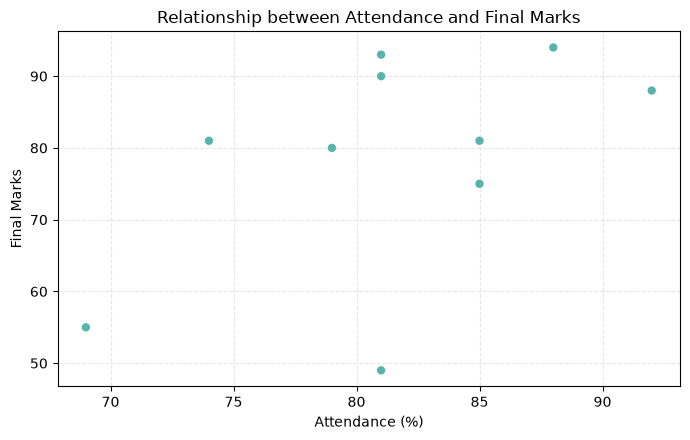

In [ ]:

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.scatter(students["attendance"], students["final"], color="#0D9488", alpha=0.7, edgecolors="none")
ax.set(
    title="Relationship between Attendance and Final Marks",
    xlabel="Attendance (%)",
    ylabel="Final Marks"
)
ax.grid(True, linestyle="--", alpha=0.3)
fig.tight_layout()


scatter_plot_path = FIGURE_DIR / "b2_attendance_vs_final.png"
fig.savefig(scatter_plot_path, dpi=300)
plt.show()

## Part C — Distributions and Comparisons

C1. Histogram: Weighted Score Distribution

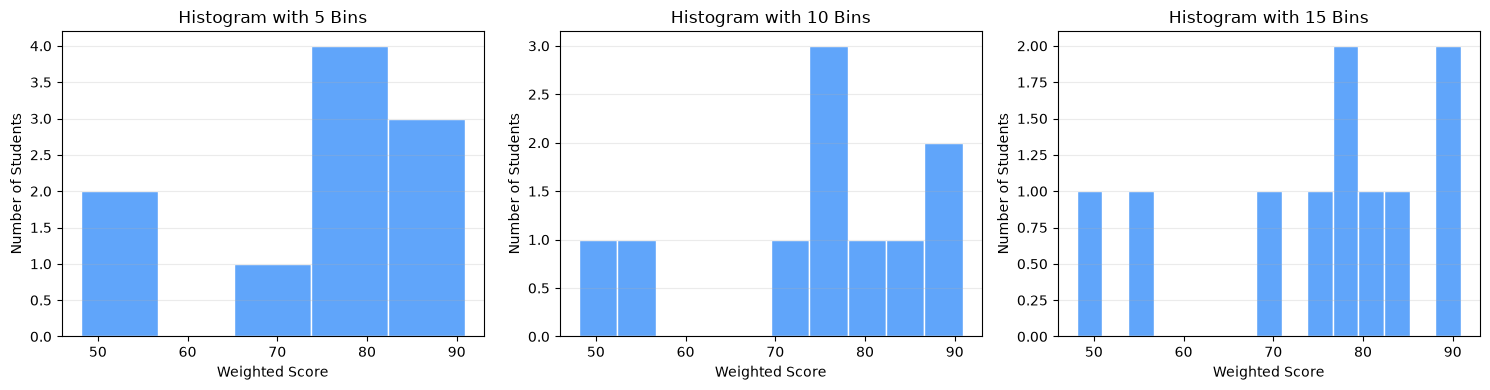

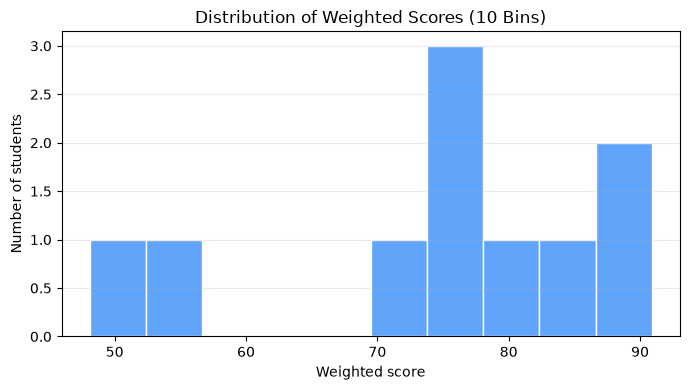

In [16]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
bin_choices = [5, 10, 15]

for ax, b in zip(axes, bin_choices):
    ax.hist(students["weighted_score"].dropna(), bins=b, color="#60A5FA", edgecolor="white")
    ax.set(title=f"Histogram with {b} Bins", xlabel="Weighted Score", ylabel="Number of Students")
    ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "c1_bin_comparison.png", dpi=300)
plt.show()


fig, ax = plt.subplots(figsize=(7, 4)) 
ax.hist(students["weighted_score"].dropna(), bins=10, color="#60A5FA", edgecolor="white") 
ax.set(
    title="Distribution of Weighted Scores (10 Bins)", 
    xlabel="Weighted score", 
    ylabel="Number of students"
) 
ax.grid(axis="y", alpha=0.25) 
fig.tight_layout()

c1_hist_path = FIGURE_DIR / "c1_weighted_score_histogram.png"
fig.savefig(c1_hist_path, dpi=300)
plt.show()

### C2. Box Plot: Five-Number Summary and Outlier Screening

C:\Users\Admin\AppData\Local\Temp\ipykernel_22148\3612654376.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(students["weighted_score"].dropna(), vert=False, patch_artist=True,


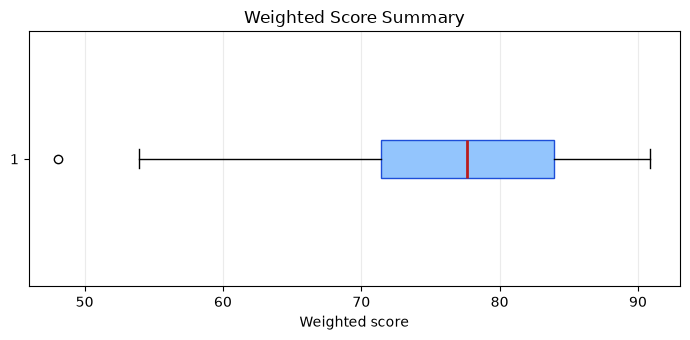

In [17]:

fig, ax = plt.subplots(figsize=(7, 3.5)) 
ax.boxplot(students["weighted_score"].dropna(), vert=False, patch_artist=True,
           boxprops=dict(facecolor="#93C5FD", color="#1D4ED8"),
           medianprops=dict(color="#B91C1C", linewidth=2)) 
ax.set(title="Weighted Score Summary", xlabel="Weighted score") 
ax.grid(axis="x", alpha=0.25) 
fig.tight_layout()

c2_box_path = FIGURE_DIR / "c2_weighted_score_boxplot.png"
fig.savefig(c2_box_path, dpi=300)
plt.show()

### C3. Bar Chart: Categorical Comparison by Program

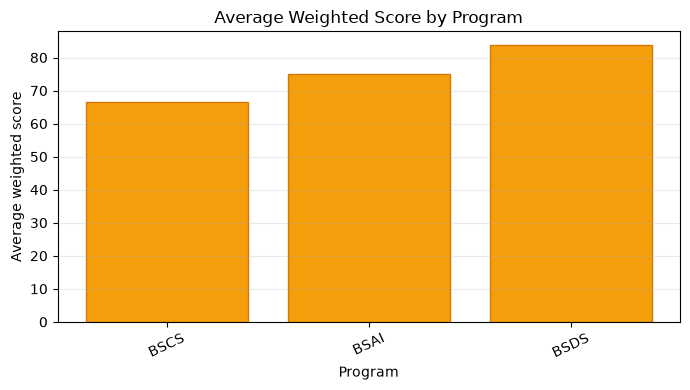

Program Mean Scores (Sorted):
program
BSCS    66.40
BSAI    74.95
BSDS    83.75
Name: weighted_score, dtype: float64

Highest Observed Average Program: BSDS (83.75)


In [18]:

program_scores = (
    students.groupby("program")["weighted_score"] 
    .mean()
    .sort_values()
) 

fig, ax = plt.subplots(figsize=(7, 4)) 
ax.bar(program_scores.index, program_scores.values, color="#F59E0B", edgecolor="#D97706") 
ax.set(
    title="Average Weighted Score by Program", 
    xlabel="Program", 
    ylabel="Average weighted score"
) 
ax.tick_params(axis="x", rotation=25) 
ax.grid(axis="y", alpha=0.25) 
fig.tight_layout()

c3_bar_path = FIGURE_DIR / "c3_program_average_scores.png"
fig.savefig(c3_bar_path, dpi=300)
plt.show()

print("Program Mean Scores (Sorted):")
print(program_scores)
print(f"\nHighest Observed Average Program: {program_scores.index[-1]} ({program_scores.iloc[-1]:.2f})")

## Part D — Build and Export a Dashboard

### D1. Create the 2 × 2 Student Performance Dashboard

C:\Users\Admin\AppData\Local\Temp\ipykernel_22148\3780017618.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, 1].boxplot(students["weighted_score"].dropna(), vert=False, patch_artist=True,


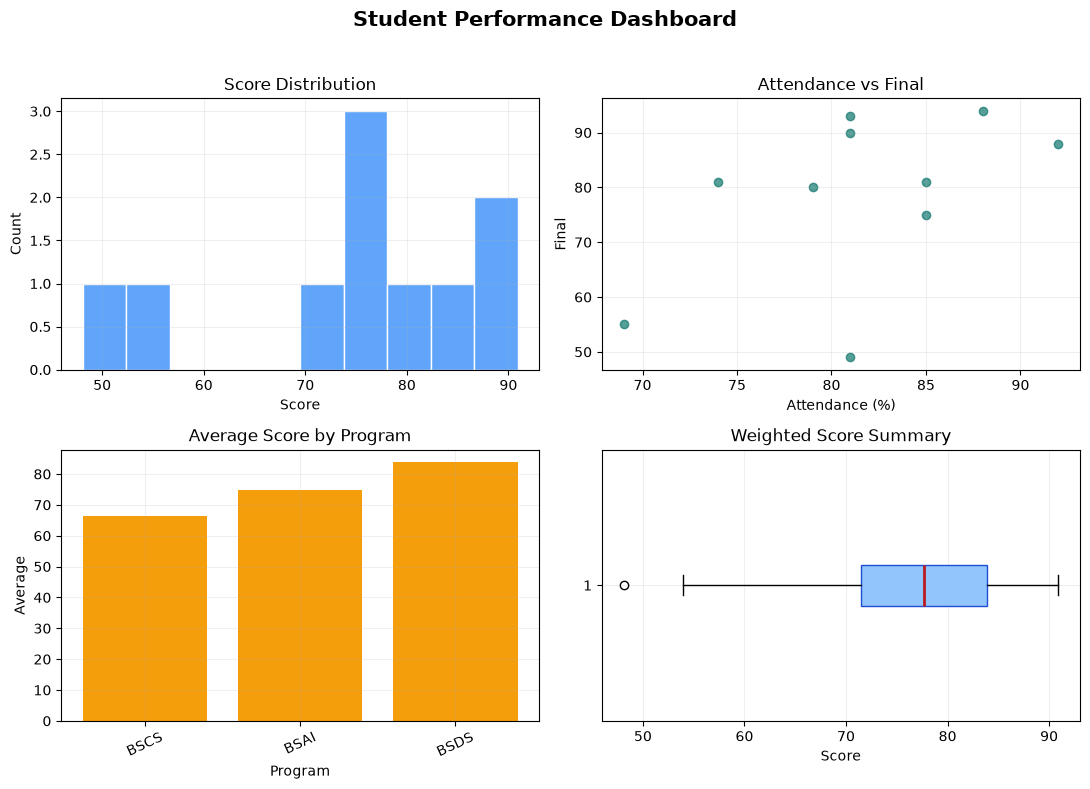

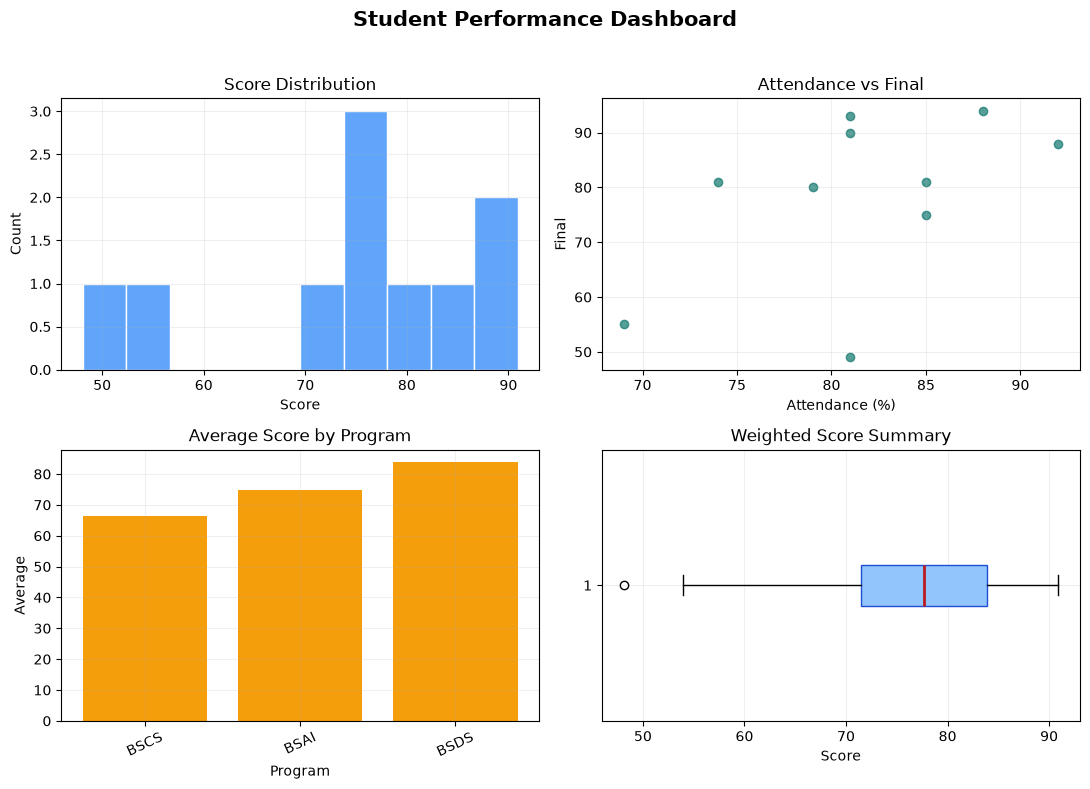

In [19]:

fig, axes = plt.subplots(2, 2, figsize=(11, 8)) 

axes[0, 0].hist(students["weighted_score"].dropna(), bins=10, color="#60A5FA", edgecolor="white") 
axes[0, 0].set(title="Score Distribution", xlabel="Score", ylabel="Count") 

axes[0, 1].scatter(students["attendance"], students["final"], alpha=0.7, color="#0F766E") 
axes[0, 1].set(title="Attendance vs Final", xlabel="Attendance (%)", ylabel="Final") 

axes[1, 0].bar(program_scores.index, program_scores.values, color="#F59E0B") 
axes[1, 0].set(title="Average Score by Program", xlabel="Program", ylabel="Average") 
axes[1, 0].tick_params(axis="x", rotation=25) 

axes[1, 1].boxplot(students["weighted_score"].dropna(), vert=False, patch_artist=True,
                   boxprops=dict(facecolor="#93C5FD", color="#1D4ED8"),
                   medianprops=dict(color="#B91C1C", linewidth=2)) 
axes[1, 1].set(title="Weighted Score Summary", xlabel="Score") 

for ax in axes.flat: 
    ax.grid(alpha=0.2) 

fig.suptitle("Student Performance Dashboard", fontsize=15, fontweight="bold") 
fig.tight_layout(rect=[0, 0, 1, 0.96])

display(fig)

### D2. Save Reproducible Output (PNG & PDF) and Assert Verification

In [20]:

png_path = FIGURE_DIR / "student_dashboard.png" 
pdf_path = FIGURE_DIR / "student_dashboard.pdf" 

fig.savefig(png_path, dpi=300, bbox_inches="tight") 
fig.savefig(pdf_path, bbox_inches="tight") 
plt.close(fig) 

assert png_path.exists() and png_path.stat().st_size > 0, "PNG file export failed or is empty!" 
assert pdf_path.exists() and pdf_path.stat().st_size > 0, "PDF file export failed or is empty!"

print(f"PNG successfully verified: {png_path} ({png_path.stat().st_size / 1024:.1f} KB)")
print(f"PDF successfully verified: {pdf_path} ({pdf_path.stat().st_size / 1024:.1f} KB)")
print("Part D completed successfully.")

PNG successfully verified: figures\student_dashboard.png (204.7 KB)
PDF successfully verified: figures\student_dashboard.pdf (26.1 KB)
Part D completed successfully.
